# Modélisation baseline : prévision naïve, régression linéaire et modèles à arbres
**Contributeurs :** Cécile · **Date :** 27/10/2026

Cible : prix médian au m² par bassin de vie, par année et par type de bien. Variable de l'année N-1 seulement. Apprentissage de 2020 à 2023, validation sur 2024 ; 2025 n'est pas utilisée (test final). Toute erreur est comparée à la prévision naïve (prix N = prix N-1).

## 1. Table de modélisation (cible seule, avant la fusion)
Une ligne par bassin, année et type de bien : prix et nombre de ventes de l'année N, prix et nombre de ventes de l'année N-1. Un prix calculé sur moins de 20 ventes n'est pas fiable : il n'est utilisé ni comme cible ni comme prix N-1. Le nombre de ventes de l'année N reste dans la table pour information, mais n'entre dans aucun modèle (inconnu au moment de prévoir).

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from commun import DATA_OUT, CIBLE, ANNEE_DEBUT, ANNEE_VALIDATION, charger_table, decouper, prevision_naive, evaluer, tester

SEUIL = 20   # ventes par bassin, par année et par type de bien (seuil retenu pour la modélisation)

# 1. Table cible au format long : une ligne par bassin x année x type de bien
cible = pd.read_parquet(DATA_OUT / "cible_bv_annee.parquet")
morceaux = []
for type_bien in ["maison", "appart"]:
    m = cible[["BV2022", "annee", f"n_{type_bien}", f"prix_m2_med_{type_bien}"]].rename(
        columns={f"n_{type_bien}": "n_ventes", f"prix_m2_med_{type_bien}": "prix"})
    m["type_bien"] = type_bien
    morceaux.append(m)
table = pd.concat(morceaux, ignore_index=True)

# Prix sous le seuil : médiane non fiable, valeur vidée (la ligne ne servira ni de cible ni de prix N-1)
table.loc[table["n_ventes"] < SEUIL, "prix"] = np.nan

# 2. Prix et nombre de ventes de l'année N-1 (même bassin, même type de bien)
precedent = table[["BV2022", "type_bien", "annee", "prix", "n_ventes"]].rename(
    columns={"prix": "prix_n1", "n_ventes": "n_ventes_n1"})
precedent["annee"] = precedent["annee"] + 1
table = table.merge(precedent, on=["BV2022", "type_bien", "annee"], how="left", validate="one_to_one")

# 3. Lignes utilisables : prix N et prix N-1 connus
avant = len(table)
table = table[table["prix"].notna() & table["prix_n1"].notna()].reset_index(drop=True)
print("Lignes gardées :", len(table), "sur", avant)
display(table.groupby(["annee", "type_bien"]).size().unstack())
print("Doublons :", table.duplicated(["BV2022", "annee", "type_bien"]).sum())

table.to_parquet(DATA_OUT / "table_modelisation_bv.parquet", index=False)

Lignes gardées : 25142 sur 38710


type_bien,appart,maison
annee,,
2015,577,1600
2016,598,1603
2017,625,1605
2018,648,1608
2019,676,1607
2020,723,1608
2021,741,1609
2022,772,1609
2023,726,1607


Doublons : 0


## 2. Découpage et prévision naïve
Apprentissage de 2020 à 2023, validation sur 2024 (fonction `decouper` de `commun.py`). Tous les modèles utilisent la même variable : le prix médian au m² de l'année N-1.

La prévision naïve prévoit pour l'année N le prix de l'année N-1. C'est la référence de tous les modèles : un modèle n'a d'intérêt que s'il fait mieux.

In [11]:
apprentissage, validation = decouper(charger_table())
VARIABLES = ["prix_n1"]   # variable utilisée par tous les modèles de ce notebook

print("Apprentissage :", apprentissage["annee"].min(), "à", apprentissage["annee"].max(), "|", len(apprentissage), "lignes")
print("Validation :", validation["annee"].unique(), "|", len(validation), "lignes")

Apprentissage : 2020 à 2023 | 9395 lignes
Validation : [2024] | 2298 lignes


## 3. Régression linéaire
Le prix de l'année N est prévu par une droite : prix N = coefficient × prix N-1 + constante, apprise sur 2020-2023. Le graphique montre cette droite (en rouge) à côté de la prévision naïve (la diagonale en pointillés, prix N = prix N-1). Chaque point est un bassin.

Coefficient : 1.064 | constante : -6.8


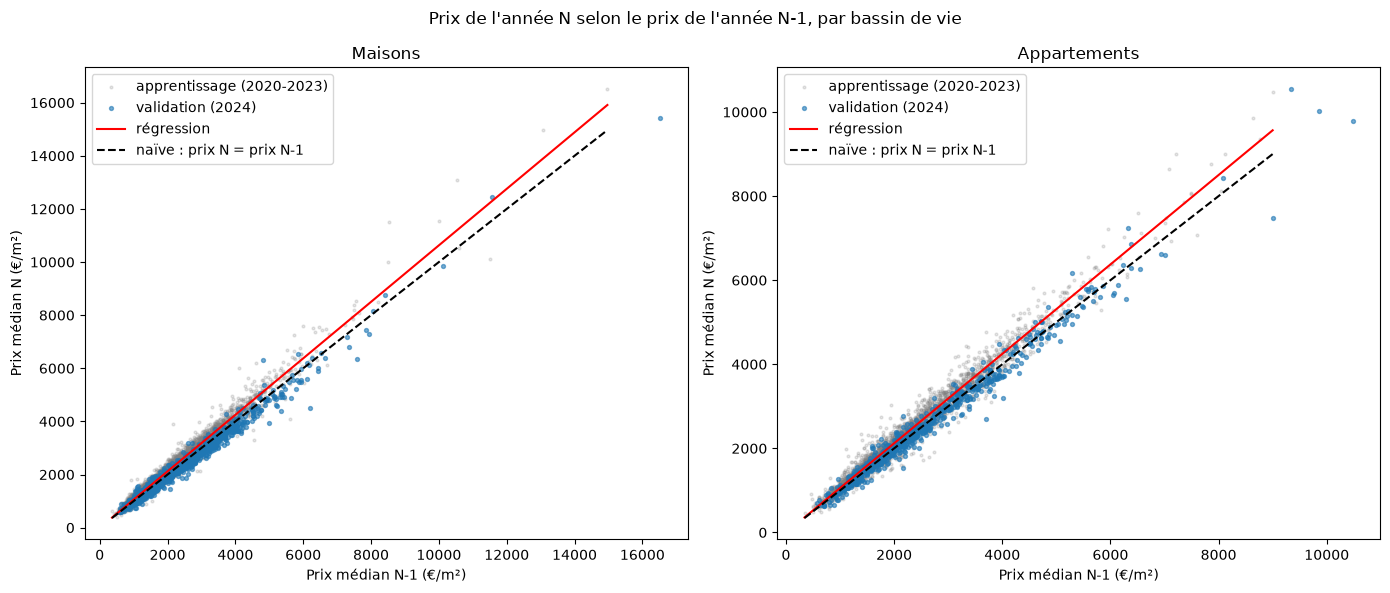

In [12]:
modele = LinearRegression()
modele.fit(apprentissage[VARIABLES], apprentissage[CIBLE])
print("Coefficient :", round(modele.coef_[0], 3), "| constante :", round(modele.intercept_, 1))

# Droite apprise, comparée à la prévision naïve (prix N = prix N-1)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (t, titre) in zip(axes, [("maison", "Maisons"), ("appart", "Appartements")]):
    a = apprentissage[apprentissage["type_bien"] == t]
    e = validation[validation["type_bien"] == t]
    ax.scatter(a["prix_n1"], a[CIBLE], s=4, alpha=0.2, color="grey", label="apprentissage (2020-2023)")
    ax.scatter(e["prix_n1"], e[CIBLE], s=8, alpha=0.6, label="validation (2024)")
    x = np.linspace(a["prix_n1"].min(), a["prix_n1"].max(), 100)
    ax.plot(x, modele.intercept_ + modele.coef_[0] * x, color="red", label="régression")
    ax.plot(x, x, color="black", linestyle="--", label="naïve : prix N = prix N-1")
    ax.set_title(titre)
    ax.set_xlabel("Prix médian N-1 (€/m²)")
    ax.set_ylabel("Prix médian N (€/m²)")
    ax.legend()
fig.suptitle("Prix de l'année N selon le prix de l'année N-1, par bassin de vie")
plt.tight_layout()
plt.show()

**Lecture :** prix N = 1,064 × prix N-1 − 6,8. Pour un bassin à 2 000 €/m² l'année N-1, le modèle prévoit 2 121 €/m², soit 121 €/m² de plus. La droite rouge est donc au-dessus de la diagonale : le modèle a appris sur 2020-2023 que les prix montent d'une année à l'autre. Les points de l'apprentissage (en gris) sont eux aussi au-dessus de la diagonale, alors que ceux de 2024 (en bleu) sont sur la diagonale ou en dessous.

## 4. Modèles à arbres
Un arbre de décision découpe les prix N-1 en tranches et prévoit, dans chaque tranche, la moyenne des prix N vus en apprentissage : il ne prévoit jamais au-delà des prix déjà vus. La forêt aléatoire fait la moyenne de 100 arbres construits sur des échantillons différents de l'apprentissage. Réglages par défaut ; le réglage des hyperparamètres est fait à l'étape d'optimisation.

In [13]:
arbres = {
    "Arbre de décision, prix N-1": DecisionTreeRegressor(random_state=42),
    "Forêt aléatoire, prix N-1": RandomForestRegressor(random_state=42, n_jobs=-1),
}
for nom, m in arbres.items():
    m.fit(apprentissage[VARIABLES], apprentissage[CIBLE])
    print(nom, ": entraîné")

Arbre de décision, prix N-1 : entraîné
Forêt aléatoire, prix N-1 : entraîné


## 5. Comparaison des modèles

### 5.1 Erreurs sur 2024
Pour chaque modèle et chaque type de bien : erreur moyenne en €/m² et en % du prix réel, erreur de la naïve, gain sur la naïve et part des bassins où le modèle fait mieux que la naïve.

In [14]:
# Prévisions de 2024 de chaque modèle
previsions = {"Naïve (prix N-1)": prevision_naive(validation),
              "Régression linéaire, prix N-1": pd.Series(modele.predict(validation[VARIABLES]), index=validation.index)}
for nom, m in arbres.items():
    previsions[nom] = pd.Series(m.predict(validation[VARIABLES]), index=validation.index)

# Tableau commun des erreurs (fonction evaluer de commun.py)
resultats = []
for nom, prevision in previsions.items():
    evaluer(nom, validation, prevision, resultats)
display(pd.DataFrame(resultats).round(2))

,modèle,type de bien,MAE (€/m²),MAE en % du prix,MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
0,Naïve (prix N-1),appart,132.75,5.64,132.75,0.00,0.00
1,Naïve (prix N-1),maison,124.46,5.99,124.46,0.00,0.00
2,"Régression linéaire, prix N-1",appart,211.09,8.68,132.75,-59.01,27.02
3,"Régression linéaire, prix N-1",maison,215.48,9.97,124.46,-73.13,18.99
4,"Arbre de décision, prix N-1",appart,237.84,9.49,132.75,-79.16,27.89
5,"Arbre de décision, prix N-1",maison,227.66,10.59,124.46,-82.92,21.79
6,"Forêt aléatoire, prix N-1",appart,224.40,9.15,132.75,-69.03,28.18
7,"Forêt aléatoire, prix N-1",maison,221.21,10.38,124.46,-77.74,20.92


**Comment lire le tableau (exemple : régression linéaire, maisons) :**
- **MAE = 215 €/m² (10,0 %)** : en moyenne, la prévision de 2024 s'écarte de 215 €/m² du prix réel, soit 10 % du prix.
- **MAE naïve = 124 €/m²** : en prévoyant pour 2024 le prix de 2023, on se trompe en moyenne de 124 €/m² seulement.
- **Gain sur la naïve = −73 %** : l'erreur du modèle est 73 % plus grande que celle de la naïve. Un gain positif voudrait dire que le modèle fait mieux.
- **Bassins où le modèle gagne = 19 %** : le modèle ne fait mieux que la naïve que dans un bassin sur cinq.

**Constat :** aucun modèle ne fait mieux que la naïve (5,6 % d'erreur pour les appartements, 6,0 % pour les maisons). La régression linéaire est le meilleur des trois modèles (8,7 et 10,0 %), devant la forêt aléatoire (9,2 et 10,4 %) et l'arbre de décision (9,5 et 10,6 %).

### 5.2 Le modèle fait-il vraiment mieux que la naïve ?
Pour chaque bassin, on calcule l'écart entre l'erreur du modèle et celle de la naïve (négatif : le modèle fait mieux). Deux tests complémentaires :
- **Bootstrap** (1 000 tirages de bassins avec remise) : écart moyen en €/m² et son intervalle de confiance à 95 %. Il dit **combien** le modèle gagne ou perd.
- **Wilcoxon apparié** : le modèle fait-il mieux dans la plupart des bassins ? Il travaille sur les rangs, donc quelques bassins extrêmes pèsent peu. Taille d'effet : corrélation rang-bisériale, de −1 (le modèle fait mieux partout) à +1 (il fait moins bien partout).

In [15]:
# Test de chaque modèle contre la naïve (fonction tester de commun.py)
tests = []
for nom, prevision in previsions.items():
    if nom != "Naïve (prix N-1)":          # la naïve ne se teste pas contre elle-même
        tester(nom, validation, prevision, tests)

tests = pd.DataFrame(tests)
display(tests.round({"écart de MAE avec la naïve (€/m²)": 1, "IC 95 % bas (€/m²)": 1,
                     "IC 95 % haut (€/m²)": 1, "rang-bisériale": 2}))

,modèle,type de bien,écart de MAE avec la naïve (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale
0,"Régression linéaire, prix N-1",appart,78.3,67.7,87.9,7.734808e-42,0.59
1,"Régression linéaire, prix N-1",maison,91.0,85.6,96.9,4.440809e-159,0.77
2,"Arbre de décision, prix N-1",appart,105.1,88.1,122.2,3.811292e-40,0.58
3,"Arbre de décision, prix N-1",maison,103.2,95.7,111.3,4.645047e-142,0.73
4,"Forêt aléatoire, prix N-1",appart,91.6,77.3,105.6,3.792165e-39,0.57
5,"Forêt aléatoire, prix N-1",maison,96.7,89.8,103.9,1.488800e-144,0.74


**Comment lire le tableau (exemple : régression linéaire, maisons) :**
- **Écart de MAE = +91,0 €/m²** : en moyenne, la régression se trompe de 91 €/m² de plus que la naïve. Un écart négatif voudrait dire que le modèle fait mieux.
- **IC 95 % de +85,6 à +96,9 €/m²** : en tirant 1 000 fois d'autres échantillons de bassins, l'écart reste dans cet intervalle 95 fois sur 100. L'intervalle ne contient pas 0 : la régression fait moins bien que la naïve, et ce n'est pas un hasard de l'échantillon.
- **p-value du Wilcoxon = 4,4 × 10⁻¹⁵⁹** : il est presque impossible d'obtenir un tel déséquilibre entre bassins gagnés et perdus si les deux prévisions se valaient. Avec plus de 1 600 bassins, la p-value est presque toujours minuscule : c'est la taille d'effet qui compte.
- **Rang-bisériale = +0,77** : la valeur va de −1 (le modèle fait mieux dans tous les bassins) à +1 (il fait moins bien partout). Repères usuels : 0,1 faible, 0,3 moyen, 0,5 fort. Ici l'effet est fort, et il est positif : la régression fait moins bien que la naïve dans la grande majorité des bassins.

**Constat :**
- **Les deux tests vont dans le même sens pour les trois modèles** : aucun intervalle ne contient 0, et toutes les tailles d'effet sont fortes (0,57 à 0,77). Les modèles font moins bien que la naïve en moyenne (de +78 à +105 €/m²) **et** dans la plupart des bassins. Le résultat de la baseline ne vient donc ni du hasard ni de quelques bassins extrêmes.
- **L'effet est plus fort pour les maisons (0,73 à 0,77) que pour les appartements (0,57 à 0,59)**, comme le montrait déjà la part des bassins où le modèle gagne (19 à 22 % pour les maisons, 27 à 28 % pour les appartements).
- **La régression linéaire reste le meilleur des trois modèles** : c'est elle qui a le plus petit écart pour les deux types de bien. Son intervalle ne recoupe pas celui de l'arbre de décision, ni pour les maisons ni pour les appartements, donc cette différence de classement est solide. En revanche, il recoupe celui de la forêt aléatoire pour les deux types de bien (par exemple 67,7-87,9 contre 77,3-105,6 pour les appartements) : on ne peut pas affirmer que la régression fait mieux que la forêt.

**Utilité pour la suite :** ces deux tests seront appliqués à chaque modèle enrichi. Un modèle ne sera retenu comme meilleur que la naïve que si l'intervalle du bootstrap est entièrement sous 0 **et** si la rang-bisériale est négative.

### 5.3 Prix prévu et prix réel
Prix prévu pour 2024 selon le prix réel, en €/m², un point par bassin et par type de bien. Plus les points sont proches de la diagonale, meilleure est la prévision ; au-dessus de la diagonale, le modèle surestime le prix.

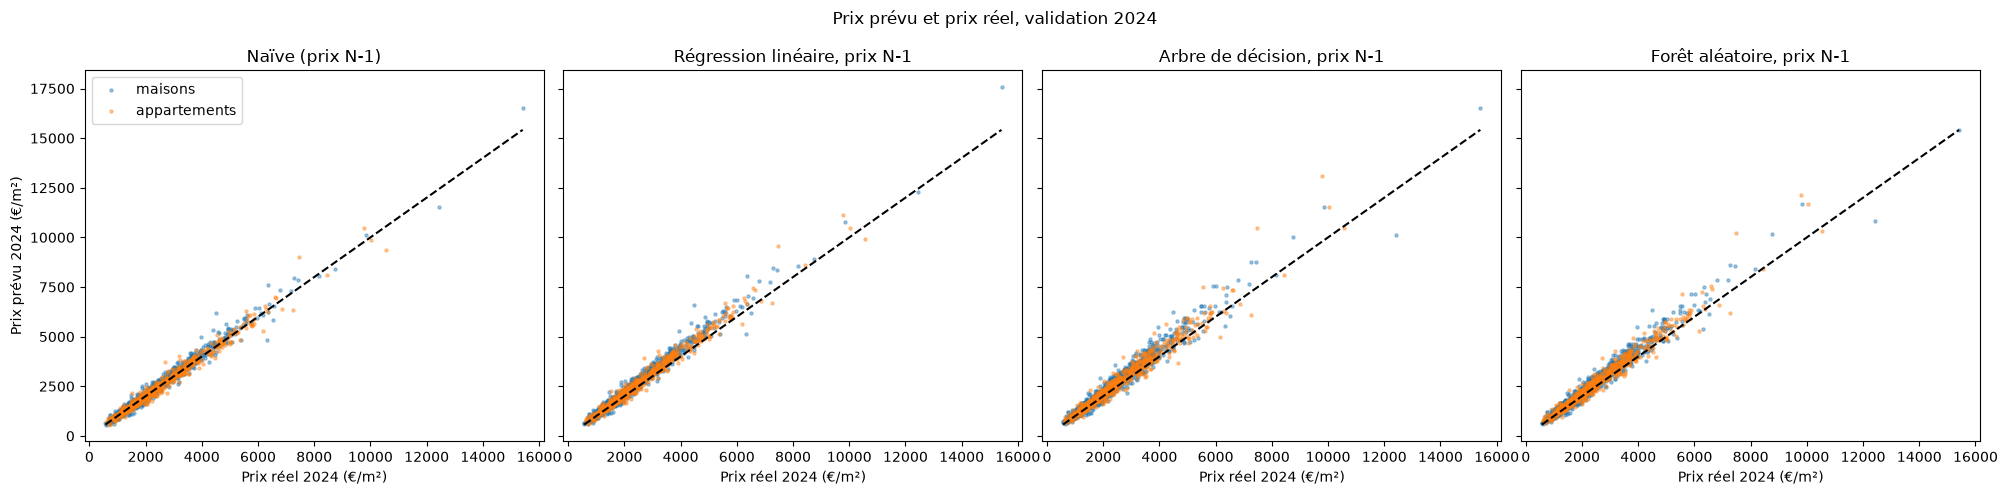

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
for ax, (nom, prevision) in zip(axes, previsions.items()):
    for t, titre in [("maison", "maisons"), ("appart", "appartements")]:
        ligne = validation["type_bien"] == t
        ax.scatter(validation.loc[ligne, CIBLE], prevision[ligne], s=5, alpha=0.4, label=titre)
    lim = [validation[CIBLE].min(), validation[CIBLE].max()]
    ax.plot(lim, lim, color="black", linestyle="--")
    ax.set_title(nom)
    ax.set_xlabel("Prix réel 2024 (€/m²)")
axes[0].set_ylabel("Prix prévu 2024 (€/m²)")
axes[0].legend()
fig.suptitle("Prix prévu et prix réel, validation 2024")
plt.tight_layout()
plt.show()

**Constat :** tous les nuages suivent la diagonale. En niveau, prévoir le prix d'un bassin à partir de son prix de l'année précédente donne toujours le bon ordre de grandeur, quel que soit le modèle. Les écarts entre modèles sont petits à cette échelle : le graphique suivant les rend visibles.

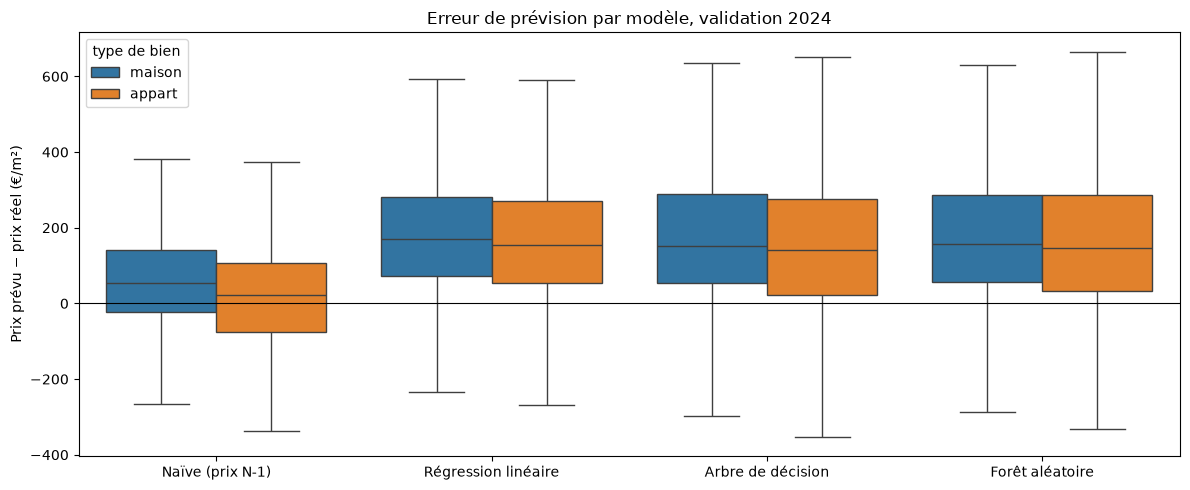

type de bien,appart,maison
modèle,,
Arbre de décision,141.0,153.0
Forêt aléatoire,146.0,157.0
Naïve (prix N-1),21.0,53.0
Régression linéaire,153.0,169.0


In [17]:
erreurs = pd.concat([pd.DataFrame({"modèle": nom.replace(", prix N-1", ""),
                                   "type de bien": validation["type_bien"],
                                   "erreur (€/m²)": prevision - validation[CIBLE]})
                     for nom, prevision in previsions.items()], ignore_index=True)

plt.figure(figsize=(12, 5))
sns.boxplot(data=erreurs, x="modèle", y="erreur (€/m²)", hue="type de bien", showfliers=False)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Prix prévu − prix réel (€/m²)")
plt.xlabel("")
plt.title("Erreur de prévision par modèle, validation 2024")
plt.tight_layout()
plt.show()

# Erreur médiane : la boîte est-elle centrée sur 0 ?
display(erreurs.groupby(["modèle", "type de bien"])["erreur (€/m²)"].median().unstack().round(0))

**Comment lire le graphique (exemple : régression linéaire, maisons) :**
- **Trait central de la boîte = 169 €/m²** : pour la moitié des bassins, la régression prévoit un prix des maisons supérieur d'au moins 169 €/m² au prix réel de 2024.
- **Boîte de 70 à 280 €/m² environ** : la moitié des bassins a une erreur comprise entre ces deux valeurs. La boîte est entièrement au-dessus de 0 : le modèle surestime le prix de la grande majorité des bassins.

**Constat :**
- **La prévision naïve est la seule centrée près de 0** : erreur médiane de +21 €/m² (appartements) et +53 €/m² (maisons). Elle surestime légèrement, car les prix ont un peu baissé en 2024.
- **Les trois modèles surestiment presque tous les bassins** : erreur médiane de +141 à +169 €/m².
- **Les boîtes des trois modèles ont la même hauteur que celle de la naïve** (environ 200 à 250 €/m²) : les modèles ne se trompent pas davantage d'un bassin à l'autre, ils se trompent surtout dans le même sens. Les moustaches des arbres sont un peu plus longues que celles de la régression.

**Interprétation :** les trois modèles ont appris sur 2020-2023 que le prix d'un bassin monte d'une année à l'autre. En 2024, les prix ont baissé : ils ajoutent tous une hausse qui n'a pas eu lieu. Le prix N-1 seul ne contient pas d'information sur ce qui distingue un bassin d'un autre d'une année sur l'autre : les modèles ne peuvent pas faire mieux que le recopier.

## 6. Conclusion

| Modèle | Erreur moyenne, appartements | Erreur moyenne, maisons | Gain sur la naïve | Bassins où le modèle gagne |
|---|---|---|---|---|
| Naïve (prix N-1) | 133 €/m² (5,6 %) | 124 €/m² (6,0 %) | référence | référence |
| Régression linéaire | 211 €/m² (8,7 %) | 215 €/m² (10,0 %) | −59 % et −73 % | 27 % et 19 % |
| Arbre de décision | 238 €/m² (9,5 %) | 228 €/m² (10,6 %) | −79 % et −83 % | 28 % et 22 % |
| Forêt aléatoire | 224 €/m² (9,2 %) | 221 €/m² (10,4 %) | −69 % et −78 % | 28 % et 21 % |

- **Avec le seul prix N-1, aucun modèle ne fait mieux que la prévision naïve** : tous ajoutent la hausse apprise sur 2020-2023 (erreur médiane de +141 à +169 €/m²), alors que les prix ont un peu baissé en 2024.
- **Ce résultat n'est pas dû au hasard** : pour les trois modèles, l'intervalle de confiance du bootstrap est entièrement au-dessus de 0 (écart de +78 à +105 €/m²) et la taille d'effet du Wilcoxon est forte (rang-bisériale de 0,57 à 0,77). Les modèles font moins bien que la naïve en moyenne et dans la plupart des bassins.
- **La régression linéaire est le meilleur des trois modèles**, devant la forêt aléatoire puis l'arbre de décision, qui apprennent en plus le bruit des médianes.
- **Baseline retenue : la prévision naïve**, référence de tous les modèles suivants. La régression linéaire avec le prix N-1 sert de premier point de comparaison pour les modèles enrichis.

**Limites :** une seule année de validation (2024), marquée par un retournement du marché ; avec une année calme, l'écart avec la naïve serait probablement plus faible (hypothèse). Réglages par défaut pour les arbres.

**Suite :** ajouter les variables des autres sources après la fusion (table au bassin commune à l'équipe), puis régler les modèles à arbres à l'étape d'optimisation.

## 7. Bassin de vie ou sous-bassin ? Comparaison des deux mailles
Même construction de la table qu'en section 1 (seuil de 20 ventes, prix N-1), appliquée aux deux mailles : bassins de vie (`cible_bv_annee`) et sous-bassins (`cible_sbv_annee`, grands bassins découpés selon la densité, arrondissements de Paris, Lyon et Marseille séparés). On compare le nombre de lignes utilisables et l'erreur de la prévision naïve sur 2024.

In [18]:
def construire_table(fichier, maille):
    """Table au format long (territoire x année x type de bien), prix N et N-1, seuil de SEUIL ventes."""
    cible = pd.read_parquet(DATA_OUT / fichier)
    morceaux = []
    for type_bien in ["maison", "appart"]:
        m = cible[[maille, "annee", f"n_{type_bien}", f"prix_m2_med_{type_bien}"]].rename(
            columns={maille: "territoire", f"n_{type_bien}": "n_ventes", f"prix_m2_med_{type_bien}": "prix"})
        m["type_bien"] = type_bien
        morceaux.append(m)
    t = pd.concat(morceaux, ignore_index=True)
    t.loc[t["n_ventes"] < SEUIL, "prix"] = np.nan
    precedent = t[["territoire", "type_bien", "annee", "prix"]].rename(columns={"prix": "prix_n1"})
    precedent["annee"] = precedent["annee"] + 1
    t = t.merge(precedent, on=["territoire", "type_bien", "annee"], how="left", validate="one_to_one")
    return t[t["prix"].notna() & t["prix_n1"].notna()]

comparaison = []
for nom, fichier, maille in [("bassin de vie", "cible_bv_annee.parquet", "BV2022"),
                             ("sous-bassin", "cible_sbv_annee.parquet", "sous_bassin_de_vie")]:
    t = construire_table(fichier, maille)
    v = t[t["annee"] == ANNEE_VALIDATION]
    for type_bien, e in v.groupby("type_bien"):
        erreur = np.abs(e[CIBLE] - e["prix_n1"])
        comparaison.append({"maille": nom, "type de bien": type_bien,
                            "territoires en 2024": e["territoire"].nunique(),
                            "lignes 2020-2023": ((t["annee"] >= ANNEE_DEBUT) & (t["annee"] < ANNEE_VALIDATION)
                                                 & (t["type_bien"] == type_bien)).sum(),
                            "MAE naïve 2024 (€/m²)": erreur.mean(),
                            "MAE naïve 2024 (%)": (erreur / e[CIBLE]).mean() * 100})

display(pd.DataFrame(comparaison).round(1))

,maille,type de bien,territoires en 2024,lignes 2020-2023,MAE naïve 2024 (€/m²),MAE naïve 2024 (%)
0,bassin de vie,appart,692,2962,132.8,5.6
1,bassin de vie,maison,1606,6433,124.5,6.0
2,sous-bassin,appart,823,3508,148.0,5.6
3,sous-bassin,maison,1777,7124,129.1,5.9


**Comment lire le tableau (exemple : sous-bassin, appartements) :**
- **823 territoires en 2024** : nombre de sous-bassins qui ont au moins 20 ventes d'appartements en 2024 et en 2023 (prix N et prix N-1 connus).
- **3 508 lignes de 2020 à 2023** : taille de l'apprentissage pour les appartements à cette maille.
- **MAE naïve = 148,0 €/m², soit 5,6 % du prix** : en prévoyant pour 2024 le prix de 2023, on se trompe en moyenne de 148 €/m².

**Constat :**
- **Le découpage en sous-bassins augmente le nombre de territoires utilisables** : +131 pour les appartements (823 contre 692) et +171 pour les maisons (1 777 contre 1 606). L'apprentissage gagne 546 lignes d'appartements et 691 de maisons. Les sous-bassins créés ont donc assez de ventes pour passer le seuil de 20 ventes.
- **La naïve est aussi précise aux deux mailles en pourcentage** : 5,6 % pour les appartements, 6,0 et 5,9 % pour les maisons. Des territoires plus petits ne donnent pas des prix médians plus instables.
- **En €/m², l'erreur est plus forte au sous-bassin pour les appartements** (148,0 contre 132,8). C'est cohérent avec un pourcentage inchangé : les territoires ajoutés sont plus chers, en particulier les arrondissements de Paris, Lyon et Marseille. Une même erreur de 5,6 % y représente plus d'euros (hypothèse : la composition des territoires ajoutés n'a pas été vérifiée).

**Conclusion :** passer aux sous-bassins ne dégrade pas la cible : même précision de la naïve, plus de territoires et plus de lignes d'apprentissage. La maille sous-bassin répond aussi à la question de l'acheteur dans le 11e arrondissement, qui a désormais son propre prix. Choix de la maille à valider en réunion.